# Calificaciones, escala maestra y la PD a través del ciclo de un grado

**Pregunta:** ¿Qué PD debe llevar cada grado de una escala de siete grados en su escala maestra, y cuánto se aleja de ese nivel a través del ciclo la tasa de incumplimiento de un solo año?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** los notebooks 01 a 04 del tema 01 (el motor, un artefacto, una primera prueba)
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este notebook puedes:

- leer la tabla de cohortes de una agencia calificadora: los grados, el estado de incumplimiento, las calificaciones retiradas y el tamaño de la cohorte;
- convertir los conteos de un año en una PD a un año por grado con el estimador de cohorte del motor, y decir qué hacen las calificaciones retiradas con ella;
- explicar por qué la PD de un año es un número en un punto del tiempo y el promedio de muchos años es el número a través del ciclo que necesita una escala maestra;
- unir ambos con el modelo de un factor (Merton-Vasicek) y leer el factor del ciclo crediticio que implica cada año;
- hallar el portafolio al que converge una matriz agrupada y la tasa de incumplimiento que lleva.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.engines import vasicek
from riskvalidation.regulatory import irb
from riskvalidation.transitions import estimators, intervals, ttc

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C04 de Contraste, la variante S&P, tal como el producto la versiona. La fuente es la publicación CEREP de ESMA, el registro donde las agencias calificadoras reportan sus calificaciones y sus transiciones (clase de licencia `mirror-allowed`, atribución en el artefacto: "Source: ESMA CEREP; tables transformed by Contraste"; https://registers.esma.europa.eu/cerep-publication/). El flujo de datos tomó las calificaciones corporativas de largo plazo de la entidad europea de S&P por categoría, las llevó a **siete grados vigentes** (AAA, AA, A, BBB, BB, B, CCC-C) más **incumplimiento**, y guardó una tabla por **cohorte** anual: las calificaciones vigentes el 1 de enero y dónde estaba cada una el 31 de diciembre.

- **Archivo que se lee:** `data/derived/C04/sp.json`, las claves `outputs.cohorts` (26 cohortes anuales), `outputs.pd` (la PD a un año por cohorte y grado bajo cuatro definiciones), `outputs.lra` (los promedios de largo plazo), `outputs.pooled` y `outputs.origination` (la matriz agrupada y la mezcla de cohortes).
- **La definición importa.** CEREP declara que "no deterministic definition of a default event has been set up" (no se fijó una definición determinista de evento de incumplimiento), así que cada PD nombra su página. Este notebook usa `d4`, la PD leída de la página de transiciones (la columna de incumplimiento sobre la cohorte menos sus retiros), el tratamiento estándar de la industria. El notebook 10 de este tema muestra cuánto mueve una PD la elección de la página.

La celda siguiente carga el artefacto e imprime lo que contiene.

In [2]:
# Cargar el artefacto (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
sp = json.loads((ROOT / "data" / "derived" / "C04" / "sp.json").read_text(encoding="utf-8"))
out = sp["outputs"]
grades, states = out["grades"], out["states"]
cohorts = out["cohorts"]
years = [c["label"] for c in cohorts]

print("agencia:", out["agency"]["name"])
print("grados:", grades)
print("cohortes anuales:", len(cohorts), "desde", years[0], "hasta", years[-1])
print("motor que calculó el artefacto:", sp["provenance"]["riskvalidation_version"])

agencia: Standard & Poor's Credit Market Services Europe Limited
grados: ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC-C']
cohortes anuales: 26 desde 2000 hasta 2025
motor que calculó el artefacto: 1.0.1


## Método

### Paso 1: la PD a un año de un grado desde una cohorte

Cada registro de cohorte guarda, para las calificaciones vigentes al inicio del año, los `counts` de dónde estaban al final (filas el grado al inicio, columnas los siete grados y el incumplimiento) y las calificaciones `withdrawn` (retiradas): las que la agencia dejó de calificar durante el año y cuyo estado final se desconoce. La cohorte 2000 es la primera de las 26.

El estimador de cohorte de Anderson y Goodman (1957, ecuaciones 2.8 y 2.9) estima la probabilidad de pasar del grado $i$ al estado $j$ en un año como la fracción de las calificaciones que partieron en $i$ y terminaron en $j$:

$$\hat p_{ij} = \frac{N_{ij}}{N_i}$$

con $N_i$ las calificaciones que partieron en $i$ y siguen observadas al final. La PD del grado $i$ es la entrada de la columna de incumplimiento, $\hat p_{i,D}$. Las retiradas no están en $N_i$: el estándar de la industria, "the method which has emerged as an industry standard" (el método que se ha impuesto como estándar de la industria; Schuermann y Hanson, 2004, nota 4), trata un retiro como no informativo y lo reparte entre los estados en proporción a sus valores, lo que equivale a quitarlo y dividir por lo que queda.

El `cohort` del motor recibe una tabla cuadrada, así que la celda siguiente agrega una fila vacía de incumplimiento (el incumplimiento es absorbente) y lo llama con `treatment="exclude"`. Imprime, por grado, las calificaciones aún observadas al final, la fracción retirada y la PD a un año, que es la columna de incumplimiento de la matriz.

In [3]:
# La tabla de 2000 hecha cuadrada con una fila vacía de incumplimiento y una llamada al estimador de cohorte
c2000 = cohorts[0]
counts = np.array(c2000["counts"], dtype=float)
withdrawn = np.append(np.array(c2000["withdrawn"], dtype=float), 0.0)
square = np.vstack([counts, np.zeros(len(states))])
m_exclude = estimators.cohort(square, withdrawn, treatment="exclude")
p2000 = m_exclude["matrix"]

print(f"{'grado':8s}{'observadas':>14s}{'retiradas':>14s}{'PD':>10s}")
for g in range(7):
    observed = int(m_exclude["row_sizes"][g])
    share = 100 * m_exclude["withdrawn_share"][g]
    print(f"{grades[g]:8s}{observed:14d}{share:13.1f}%{100 * p2000[g, -1]:9.2f}%")

grado       observadas     retiradas        PD
AAA                229          5.0%     0.00%
AA                 852          7.7%     0.00%
A                 1637          6.0%     0.24%
BBB               1656          5.4%     0.36%
BB                1016          7.1%     0.30%
B                  951         11.1%     5.57%
CCC-C              109         23.2%    17.43%


La figura dibuja la matriz completa, cada fila el grado al inicio de 2000 y cada columna el estado al final, en porcentaje. El peso está en la diagonal y a un escalón de ella, y la columna de incumplimiento es casi cero salvo en los grados más débiles.

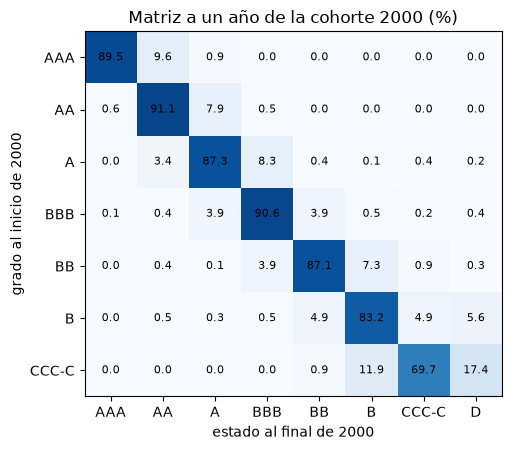

In [4]:
# Dibujar la matriz a un año de la cohorte 2000, en porcentaje, con cada celda escrita encima
fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.imshow(p2000[:7], cmap="Blues", vmin=0, vmax=1)
for i in range(7):
    for j in range(8):
        ax.text(j, i, f"{100 * p2000[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(8))
ax.set_xticklabels(states)
ax.set_yticks(range(7))
ax.set_yticklabels(grades)
ax.set_xlabel("estado al final de 2000")
ax.set_ylabel("grado al inicio de 2000")
ax.set_title("Matriz a un año de la cohorte 2000 (%)")
fig.tight_layout()
plt.show()

Lee la matriz fila por fila. Una calificación BBB de 2000 siguió siendo BBB nueve de cada diez veces y se movió un escalón arriba o abajo casi todas las demás; AAA nunca cayó en incumplimiento y AA tampoco. Los primeros incumplimientos aparecen en A, con una PD bajo 0,3%, y suben a 5,57% en B y 17,43% en CCC-C. La figura no muestra cuánto se pueden creer estos números: una celda con pocas calificaciones detrás se mueve mucho con un solo evento, y tampoco muestra lo que ocultan las retiradas, que es el paso siguiente.

### Paso 2: qué hacen las calificaciones retiradas a una PD

Si un retiro no es informativo, quitarlo es inocuo. Si una calificación se retira porque el deudor está en problemas, quitarla subestima la PD. El otro tratamiento del motor, `treatment="state"`, mantiene las retiradas en el denominador como un noveno estado absorbente, que es como el párrafo 76 de EBA/GL/2017/16 mantiene las obligaciones cerradas en la muestra. La celda siguiente corre el estimador de cohorte una segunda vez con ese tratamiento y pone las dos PD lado a lado.

In [5]:
# La misma cohorte con las retiradas mantenidas como estado absorbente, junto a la remoción
m_state = estimators.cohort(square, withdrawn, treatment="state")
pd_removed = p2000[:7, -1]
pd_kept = m_state["matrix"][:7, len(states) - 1]   # la columna 7 es el incumplimiento, la 8 el estado retirado

print(f"{'grado':8s}{'quitadas':>12s}{'mantenidas':>12s}{'razón':>8s}")
for g in range(2, 7):
    ratio = pd_removed[g] / pd_kept[g]
    print(f"{grades[g]:8s}{100 * pd_removed[g]:11.2f}%{100 * pd_kept[g]:11.2f}%{ratio:8.2f}")

grado       quitadas  mantenidas   razón
A              0.24%       0.23%    1.06
BBB            0.36%       0.34%    1.06
BB             0.30%       0.27%    1.08
B              5.57%       4.95%    1.13
CCC-C         17.43%      13.38%    1.30


La celda siguiente dibuja las dos PD de los grados especulativos lado a lado, en un eje logarítmico para que A y CCC-C puedan compartirlo.

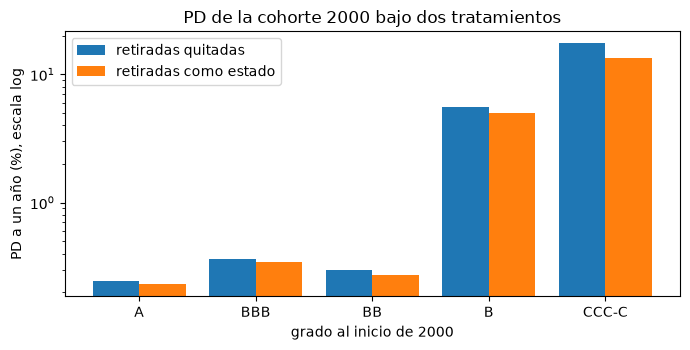

In [6]:
# Dibujar la PD de las calificaciones especulativas con las retiradas quitadas y mantenidas
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(5)
ax.bar(x - 0.2, 100 * pd_removed[2:], 0.4, color="tab:blue", label="retiradas quitadas")
ax.bar(x + 0.2, 100 * pd_kept[2:], 0.4, color="tab:orange", label="retiradas como estado")
ax.set_xticks(x)
ax.set_xticklabels(grades[2:])
ax.set_yscale("log")
ax.set_xlabel("grado al inicio de 2000")
ax.set_ylabel("PD a un año (%), escala log")
ax.set_title("PD de la cohorte 2000 bajo dos tratamientos")
ax.legend()
fig.tight_layout()
plt.show()

Mantener las calificaciones retiradas baja todas las PD, y la brecha crece a medida que el grado empeora: es de cerca de 6% en A y BBB, 13% en B y 30% en CCC-C, los grados donde la agencia retiró la mayor fracción de sus calificaciones (11% de B y 23% de CCC-C en 2000). La figura muestra que la elección pesa más justo donde más pesa la PD. No puede decir cuál tratamiento es el correcto: eso depende de si un retiro dice algo del deudor, un supuesto que el notebook 10 de este tema pone a prueba sobre trayectorias de calificación cuya verdad se conoce.

### Paso 3: de un año a la PD a través del ciclo

La PD de un año es un número en un punto del tiempo: se mueve con la economía. La escala maestra de un sistema de calificación necesita la PD a través del ciclo (TTC) de cada grado, el nivel que el grado tiene en un ciclo completo. Las guías de la EBA (EBA/GL/2017/16, párrafo 84) la definen como el promedio de largo plazo de las tasas de incumplimiento a un año, "the observed average of the one-year default rates" (el promedio observado de las tasas de incumplimiento a un año), sobre las cohortes donde el grado tiene calificaciones:

$$\mathrm{LRA}_i = \frac{1}{T_i} \sum_{t=1}^{T_i} \hat p_{i,D}(t)$$

La celda siguiente corre el estimador de cohorte sobre cada una de las 26 tablas anuales y guarda la columna de incumplimiento de cada una, lo que da la PD anual de cada grado.

In [7]:
# Una llamada del estimador de cohorte por tabla anual, con la columna de incumplimiento de cada una como PD de ese año
tables = []
gone = []
yearly = []
for c in cohorts:
    tables.append(np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]))
    gone.append(np.append(np.array(c["withdrawn"], dtype=float), 0.0))
    matrix = estimators.cohort(tables[-1], gone[-1], treatment="exclude")["matrix"]
    yearly.append(matrix[:7, -1])
yearly = np.array(yearly)
lra = yearly.mean(axis=0)
print("PD anuales calculadas:", yearly.shape[0], "años x", yearly.shape[1], "grados")

PD anuales calculadas: 26 años x 7 grados


Las tasas anuales son ruidosas donde el grado es delgado, así que el promedio solo puede engañar. La tasa agrupada (todos los incumplimientos sobre todas las calificaciones, de modo que las cohortes grandes pesan más) responde una pregunta algo distinta que el promedio de las tasas anuales, y admite un intervalo. La celda siguiente agrupa las 26 tablas con el `pooled_cohort` del motor y pone un intervalo de Jeffreys de 95% a la tasa agrupada de cada grado (Brown, Cai y DasGupta, 2001), y luego imprime el promedio, el mejor y el peor año y el intervalo.

In [8]:
# Agrupar las 26 tablas, poner un intervalo de Jeffreys a cada tasa agrupada y tabular el promedio y los años extremos
pooled = estimators.pooled_cohort(tables, gone, treatment="exclude")
defaults = pooled["counts"][:7, -1]
ratings = pooled["row_sizes"][:7]
interval = intervals.pd_jeffreys(defaults, ratings, level=0.95)

print(f"{'grado':8s}{'LRA':>9s}{'mejor año':>16s}{'peor año':>16s}"
      f"{'agrupada':>10s}{'intervalo 95%':>22s}")
for g in range(7):
    lo, hi = int(yearly[:, g].argmin()), int(yearly[:, g].argmax())
    low_txt = f"{years[lo]} {100 * yearly[lo, g]:.2f}%"
    high_txt = f"{years[hi]} {100 * yearly[hi, g]:.2f}%"
    span = f"{100 * interval['lower'][g]:.3f}% a {100 * interval['upper'][g]:.3f}%"
    pooled_rate = 100 * defaults[g] / ratings[g]
    print(f"{grades[g]:8s}{100 * lra[g]:8.3f}%{low_txt:>16s}{high_txt:>16s}{pooled_rate:9.3f}%{span:>22s}")

grado         LRA       mejor año        peor año  agrupada         intervalo 95%
AAA        0.000%      2000 0.00%      2000 0.00%    0.000%       0.000% a 0.132%
AA         0.005%      2000 0.00%      2008 0.13%    0.005%       0.001% a 0.023%
A          0.030%      2003 0.00%      2001 0.25%    0.029%       0.016% a 0.048%
BBB        0.079%      2003 0.00%      2002 0.53%    0.082%       0.058% a 0.112%
BB         0.336%      2006 0.00%      2001 2.16%    0.346%       0.279% a 0.425%
B          1.330%      2007 0.00%      2000 5.57%    1.173%       1.059% a 1.296%
CCC-C      8.608%      2021 1.58%     2009 23.86%    8.068%       7.226% a 8.974%


La celda siguiente dibuja, para los tres grados más débiles, la PD de cada año de cohorte como una barra y el promedio de largo plazo como una línea horizontal.

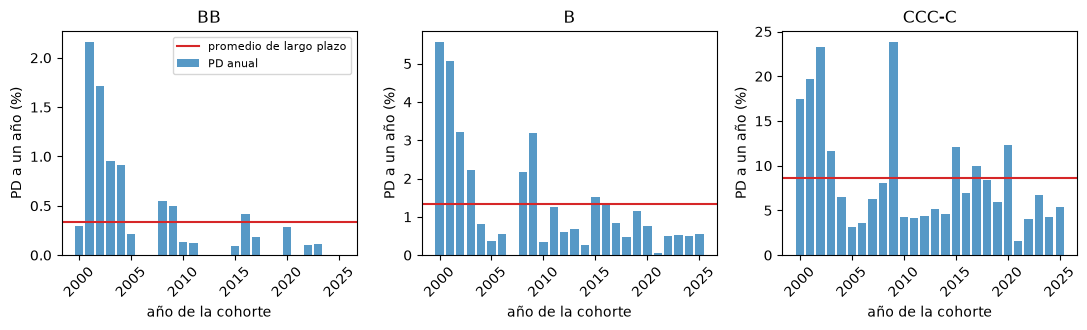

In [9]:
# Dibujar la PD anual de BB, B y CCC-C como barras con el promedio de largo plazo como línea
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, g in zip(axes, (4, 5, 6)):
    ax.bar(range(len(years)), 100 * yearly[:, g], color="tab:blue", alpha=0.75, label="PD anual")
    ax.axhline(100 * lra[g], color="tab:red", label="promedio de largo plazo")
    ax.set_xticks(range(0, len(years), 5))
    ax.set_xticklabels(years[::5], rotation=45)
    ax.set_title(grades[g])
    ax.set_xlabel("año de la cohorte")
    ax.set_ylabel("PD a un año (%)")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

La tasa anual oscila alrededor de su promedio (nótense las escalas verticales distintas): B va de cero a 5,57% alrededor de un promedio de 1,33%, y CCC-C de 1,58% a 23,86% alrededor de 8,61%. La tabla nombra los años detrás de los extremos, 2000 a 2002 y 2009 para los grados débiles, las dos recesiones de la muestra. El promedio es el número que usa una escala maestra, y la tasa anual es lo que reporta un sistema en un punto del tiempo. La figura no dice cuánto de la oscilación es la economía y cuánto es azar en una cohorte de unos cientos de calificaciones; el intervalo de la tabla da esa escala para la tasa agrupada.

### Paso 4: el vínculo entre ambas, el modelo de un factor

¿Por qué la tasa anual oscila alrededor del promedio? El modelo de Merton-Vasicek da a cada deudor un retorno de activos $A = \sqrt{\rho}\, Z + \sqrt{1-\rho}\, \varepsilon$, con un factor sistemático $Z$ compartido por todos los deudores (la economía) y uno idiosincrático $\varepsilon$; el deudor cae en incumplimiento cuando $A$ queda bajo $\Phi^{-1}(p)$, donde $p$ es la PD a través del ciclo. Dado el estado de la economía $Z = z$, la probabilidad de incumplimiento, la PD en un punto del tiempo, es

$$p_{\mathrm{PIT}}(z) = \Phi\!\left(\frac{\Phi^{-1}(p) - \sqrt{\rho}\, z}{\sqrt{1-\rho}}\right)$$

(Vasicek, 2002). Un $z$ bajo es un mal año. Invirtiendo la fórmula, una tasa de incumplimiento anual observada $\mathrm{DR}_t$ implica el factor $z_t = \bigl(\Phi^{-1}(p) - \sqrt{1-\rho}\,\Phi^{-1}(\mathrm{DR}_t)\bigr)/\sqrt{\rho}$: el índice del ciclo crediticio de ese año. El motor tiene ambos sentidos, `vasicek.conditional_pd` y `vasicek.implied_factor`. La correlación de activos $\rho$ es un supuesto: la celda siguiente toma el valor corporativo de Basilea III que da `irb.correlation` a la PD TTC del grado (el valor de la fórmula IRB, no una estimación con estos datos). Se usa el grado B porque tiene incumplimientos en casi todos los años; un año con tasa exactamente cero no implica ningún factor finito y se deja fuera.

In [10]:
# El factor del ciclo crediticio que implica cada año para el grado B, y la PD que implican factores de -2 a +2
ttc_pd = float(lra[5])
rho = irb.correlation("corporate", ttc_pd)
rate = yearly[:, 5]
usable = rate > 0
z = vasicek.implied_factor(rate[usable], ttc_pd, rho)
used_years = [yr for yr, ok in zip(years, usable) if ok]
order = np.argsort(z)
grid = np.array([-2.0, -1.0, 0.0, 1.0, 2.0])
pit = vasicek.conditional_pd(ttc_pd, rho, grid)

print("PD TTC de B:", f"{100 * ttc_pd:.2f}%", "| rho:", round(rho, 4))
print("años con tasa de incumplimiento sobre cero:", len(z), "de", len(years))
print("factores más bajos:", [(used_years[k], round(float(z[k]), 2)) for k in order[:3]])
print("factores más altos:", [(used_years[k], round(float(z[k]), 2)) for k in order[::-1][:3]])
print("PD en un punto del tiempo con z = -2, -1, 0, 1, 2:",
      [f"{100 * v:.2f}%" for v in pit])

PD TTC de B: 1.33% | rho: 0.1817
años con tasa de incumplimiento sobre cero: 25 de 26
factores más bajos: [('2000', -1.82), ('2001', -1.73), ('2002', -1.28)]
factores más altos: [('2021', 1.62), ('2014', 0.7), ('2010', 0.54)]
PD en un punto del tiempo con z = -2, -1, 0, 1, 2: ['6.57%', '2.39%', '0.71%', '0.17%', '0.03%']


La celda siguiente dibuja dos paneles: el factor que implica cada año para el grado B, y la curva que convierte cualquier factor en una PD en un punto del tiempo.

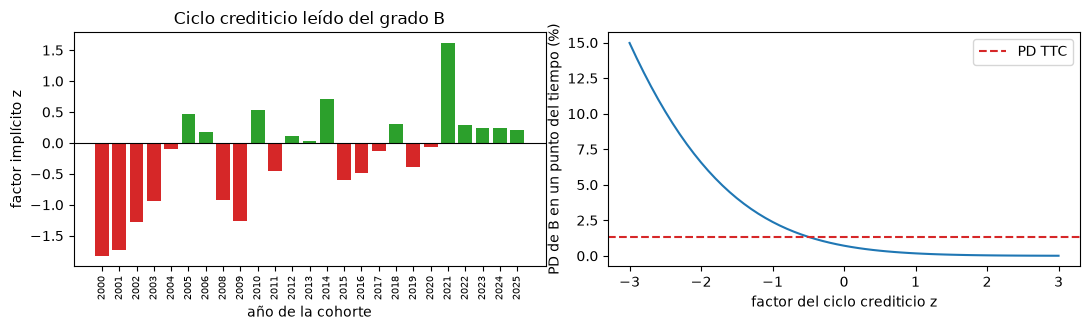

In [11]:
# Dibujar el factor que implica cada año (izquierda) y la PD en un punto del tiempo a la que corresponde (derecha)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4))
left.bar(range(len(z)), z, color=["tab:red" if v < 0 else "tab:green" for v in z])
left.axhline(0, color="black", linewidth=0.8)
left.set_xticks(range(len(z)))
left.set_xticklabels(used_years, rotation=90, fontsize=7)
left.set_xlabel("año de la cohorte")
left.set_ylabel("factor implícito z")
left.set_title("Ciclo crediticio leído del grado B")
zz = np.linspace(-3, 3, 61)
right.plot(zz, 100 * vasicek.conditional_pd(ttc_pd, rho, zz), color="tab:blue")
right.axhline(100 * ttc_pd, color="tab:red", linestyle="--", label="PD TTC")
right.set_xlabel("factor del ciclo crediticio z")
right.set_ylabel("PD de B en un punto del tiempo (%)")
right.legend()
fig.tight_layout()
plt.show()

A la izquierda, las barras bajo cero son los años peores que el ciclo promedio: 2000, 2001, 2002 y 2009 son los más bajos, como sugieren las recesiones. La media de los factores usables es -0,21 y no el cero de una normal estándar. Veintiséis años desde 2000 son una muestra pequeña de un ciclo, y la correlación es un supuesto, así que el factor es un índice del ciclo y no una medición de él. A la derecha, el modelo convierte un factor en una PD: un mal año de dos desviaciones estándar lleva la PD de B de su promedio de 1,33% a 6,57%, y un buen año del mismo tamaño la baja a 0,03%. La PD responde a los malos años mucho más que a los buenos.

### Paso 5: el portafolio TTC de la matriz agrupada

Una matriz da la PD TTC de una segunda manera. Si el portafolio se propaga año tras año con la matriz anual agrupada, con su parte en incumplimiento castigada y reoriginada con la mezcla de cohortes observada, converge a un solo portafolio, el portafolio a través del ciclo $W_{\mathrm{ttc}}$ de Engelmann (2024), cuya tasa de incumplimiento es $W_{\mathrm{ttc}}' T V_w$ (con $V_w$ la columna de incumplimiento). El `ttc_portfolio` del motor itera ese mapa. Toma la matriz agrupada del paso anterior y la mezcla de origen que guarda el artefacto, y la celda siguiente imprime cuándo converge y qué lleva. El notebook 07 desarrolla la fórmula y su deriva.

In [12]:
# Iterar la matriz agrupada con la mezcla de origen observada hasta que el portafolio deja de moverse
origination = np.array(out["origination"], dtype=float)
result = ttc.ttc_portfolio(pooled["matrix"], origination)

print("iteraciones:", result["iterations"], "| convergió:", result["converged"])
print("tasa de incumplimiento del portafolio TTC:", f"{100 * result['default_rate']:.2f}%")
latest = sp["impact"]["latest_default_rate"]["value"]
print("tasa de incumplimiento de la mezcla de la última cohorte, del artefacto:",
      f"{100 * latest:.2f}%")

iteraciones: 697 | convergió: True
tasa de incumplimiento del portafolio TTC: 0.61%
tasa de incumplimiento de la mezcla de la última cohorte, del artefacto: 0.77%


La celda siguiente pone la mezcla de origen junto al portafolio al que llegó la iteración, estado por estado.

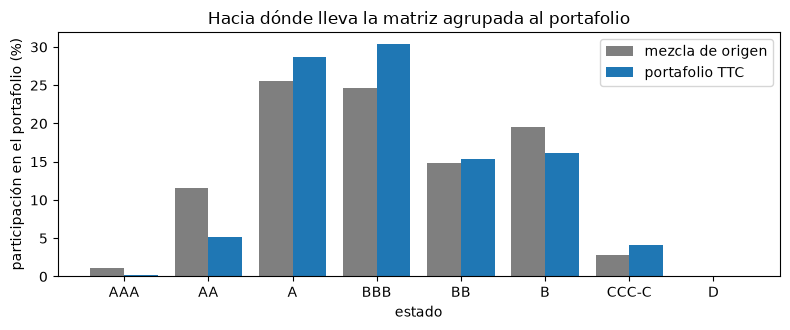

In [13]:
# Dibujar la mezcla de origen y el portafolio a través del ciclo al que converge
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(states))
ax.bar(x - 0.2, 100 * origination, 0.4, color="tab:gray", label="mezcla de origen")
ax.bar(x + 0.2, 100 * result["portfolio"], 0.4, color="tab:blue", label="portafolio TTC")
ax.set_xticks(x)
ax.set_xticklabels(states)
ax.set_xlabel("estado")
ax.set_ylabel("participación en el portafolio (%)")
ax.set_title("Hacia dónde lleva la matriz agrupada al portafolio")
ax.legend()
fig.tight_layout()
plt.show()

El portafolio a través del ciclo se aleja de la mezcla que origina el banco: tiene más A, BBB y CCC-C y menos AAA, AA y B, porque la matriz mueve las calificaciones hacia el centro de la escala y los incumplimientos castigados se reemplazan por la mezcla fija. Su tasa de incumplimiento es 0,61%, frente a 0,77% de la mezcla de la última cohorte, así que el nivel de la PD del portafolio depende de la mezcla con que se pesan los grados, no solo de las PD de los grados. Las barras no muestran la velocidad de la convergencia ni su sensibilidad a las retiradas; el notebook 07 retoma la deriva.

## Resultados

**Respuesta:** la PD de escala maestra de un grado es el promedio de sus tasas anuales: 0,005% para AA, 0,030% para A, 0,079% para BBB, 0,34% para BB, 1,33% para B y 8,61% para CCC-C, subiendo con el grado. Un solo año se aleja mucho de ella: el grado B estuvo en 5,57% en 2000 y CCC-C en 17,43%, y todo el rango de CCC-C va de 1,58% a 23,86%. La tasa anual depende del ciclo, así que una PD de un año no es una PD de escala maestra.

- **Las calificaciones retiradas mueven la PD.** Mantenerlas como estado absorbente baja la PD de B en 2000 de 5,57% a 4,95% y la de CCC-C de 17,43% a 13,38%, porque el 11,1% de las calificaciones B y el 23,2% de las CCC-C se retiraron dentro del año. Que un retiro no diga nada del deudor es un supuesto.
- **El ciclo se puede leer.** Con la correlación corporativa de Basilea III (un supuesto, 0,18 a la PD de B), la tasa de incumplimiento anual del grado B implica un factor del ciclo crediticio cuyos años más bajos son 2000, 2001 y 2002.
- **Una segunda ruta al mismo nivel.** Iterar la matriz agrupada con la mezcla de origen observada da un portafolio a través del ciclo cuya tasa de incumplimiento es 0,61%, frente a 0,77% de la mezcla de la última cohorte.

Lo que este notebook no muestra: en qué se diferencian los estimadores de cohorte, de duración y de Aalen-Johansen (notebook 02), si una matriz anual describe a una cohorte durante varios años (notebook 04), ni cómo una PD se vuelve capital (notebook 07).

## Resumen

- La tabla de cohortes de una agencia da, por grado, dónde estaban las calificaciones un año después; la fracción que terminó en incumplimiento, sobre las calificaciones aún observadas, es la PD a un año del grado.
- Las calificaciones retiradas se quitan en el tratamiento de la industria y se mantienen en la lectura del párrafo 76 de la EBA; ambas difieren más en los grados más débiles.
- Una escala maestra necesita la PD a través del ciclo, el promedio de muchas tasas anuales; el modelo de un factor une ambas y lee un factor del ciclo crediticio de cada año.
- Una matriz agrupada, iterada con la mezcla de origen, lleva a un portafolio cuya tasa de incumplimiento es una segunda lectura del nivel a través del ciclo.

**Qué probar después.** Cambia el grado del Paso 4 de B a BB y compara los peores años; luego lee el notebook 02 y sigue con el estimador de duración.

## Referencias

- ESMA, CEREP publication of credit rating agency ratings and transitions, with the help file ESMA65-8-10634. https://registers.esma.europa.eu/cerep-publication/
- Anderson, T. W. and Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1), equations 2.8 and 2.9. https://doi.org/10.1214/aoms/1177707039
- Schuermann, T. and Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190, footnote 4. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- EBA (2017), Guidelines on PD estimation, LGD estimation and the treatment of defaulted exposures, EBA/GL/2017/16, paragraphs 76, 84 and 86.
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162.
- Engelmann, B. (2024), Spurious default probability projections in credit risk stress testing models, arXiv 2401.08892.